# 14combine: who lives where it flooded, and how well served are they today? (Stage 5, part 1 of 2)

Stage 5 joins three earlier Stages on the same hexagons:

- **Stage 4:** the radar flood signal of December 2021, in two tiers (*strong*: both days; *possible*: one day)
- **Stage 2:** the 15-minute walking score (0 to 5 everyday services within 15 minutes' walk)
- **Stage 3:** Rapid KL and MRT feeder buses per hour within 400 m, and the gaps in the Rapid KL network

**Poorly served** means both: a walking score of 2 or less, **and** a gap in the Rapid KL network
(fewer than 4 buses an hour in the weekday morning peak and no rail station within a 15-minute walk).

**Honest limits:** the floods are from 2021, the services and timetables are current. The flood signal is a minimum
(images 2 to 4 days after the peak; radar misses water between tall buildings), and most of the possible tier comes
from one image only. The bus data is Prasarana only, so Klang and Sepang have more buses than shown.

- Input: `hex_flood.parquet` (Stage 4), `hex_access.parquet` (Stage 2), `hex_buses.parquet` (Stage 3)
- Output: `data/processed/hex_story.parquet`, `data/processed/story_summary.json`, `output/stage5_story_preview.png`
- Next: `15buildstory.ipynb`

## Section 0: settings

In [1]:
from pathlib import Path

BASE = Path.cwd()
PROCESSED = BASE / "data" / "processed"
OUTPUT = BASE / "output"

# Flood tiers (same as 13buildfloods)
STRONG_T = 0.05            # <- strong: at least 5% of the hexagon flagged on BOTH flood days
POSSIBLE_T = 0.05          # <- possible: at least 5% flagged on ONE flood day

# Poorly served = low walking score AND a gap in the Rapid KL network (gap rule set in 08busaccess)
POOR_SCORE_MAX = 2         # <- walking score 0, 1 or 2 of 5 counts as low

# Story places: the camera stops of the story page. Numbers are counted over the hexagons
# whose centre lies within radius_km of the point. (name, lat, lon, radius_km, note)
STORY_PLACES = [            # <-
    ("Taman Sri Muda", 3.028, 101.537, 2.0, "Whole township flooded 19 to 21 December 2021"),
    ("Meru and Bukit Raja, Klang", 3.128, 101.435, 2.5, "Meru to Bukit Raja road 2 to 3 m deep on 18 December"),
    ("Dengkil and Salak Tinggi", 2.840, 101.685, 5.0, "Over 3,500 homes submerged in Dengkil"),
    ("Central Kuala Lumpur", 3.150, 101.695, 2.0, "Dataran Merdeka and Jalan Masjid India flooded around 18 December"),
]

In [2]:
import json
import numpy as np
import pandas as pd

flood = pd.read_parquet(PROCESSED / "hex_flood.parquet")
access = pd.read_parquet(PROCESSED / "hex_access.parquet")
buses = pd.read_parquet(PROCESSED / "hex_buses.parquet")
print(f"flood {len(flood):,} | access {len(access):,} | buses {len(buses):,} hexagons")

flood 4,003 | access 4,003 | buses 4,003 hexagons


## Step 1: join the three Stages on the hexagon code

In [3]:
d = (flood[["h3", "district", "population", "F_a", "F_b", "flood_either", "flood_both"]]
     .merge(access[["h3", "lat", "lon", "score", "healthcare_min", "school_min", "park_min", "grocery_min", "rail_min"]],
            on="h3", how="inner", validate="1:1")
     .merge(buses[["h3", "stops_400m", "routes_400m", "weekday_peak", "weekday_allday", "weekend_allday", "rapid_gap"]],
            on="h3", how="inner", validate="1:1"))
assert len(d) == len(flood) == len(access) == len(buses), "the three tables do not have the same hexagons"

d["tier"] = "none"
d.loc[d["flood_either"] >= POSSIBLE_T, "tier"] = "possible"
d.loc[d["flood_both"] >= STRONG_T, "tier"] = "strong"
d["poor"] = (d["score"] <= POOR_SCORE_MAX) & d["rapid_gap"]
d["flooded"] = d["tier"] != "none"
print(f"{len(d):,} hexagons joined")
print(d["tier"].value_counts().to_string())

4,003 hexagons joined
tier
none        3790
possible     195
strong        18


## Step 2: how many people in each group are poorly served?

In [4]:
def group_stats(x):
    people = int(x["population"].sum())
    poor = int(x.loc[x["poor"], "population"].sum())
    return {
        "hexagons": int(len(x)),
        "people": people,
        "poor_people": poor,
        "poor_share": round(poor / people, 4) if people else None,
        "low_score_people": int(x.loc[x["score"] <= POOR_SCORE_MAX, "population"].sum()),
        "rapid_gap_people": int(x.loc[x["rapid_gap"], "population"].sum()),
        "no_peak_bus_people": int(x.loc[x["weekday_peak"] == 0, "population"].sum()),
        "avg_score": round(float(np.average(x["score"], weights=x["population"])), 2) if people else None,
        "avg_peak_buses": round(float(np.average(x["weekday_peak"], weights=x["population"])), 1) if people else None,
    }

groups = {
    "strong": group_stats(d[d["tier"] == "strong"]),
    "possible": group_stats(d[d["tier"] == "possible"]),
    "flooded": group_stats(d[d["flooded"]]),
    "not_flooded": group_stats(d[~d["flooded"]]),
    "valley": group_stats(d),
}
table = pd.DataFrame(groups).T
print(table.to_string())

             hexagons     people  poor_people  poor_share  low_score_people  rapid_gap_people  no_peak_bus_people  avg_score  avg_peak_buses
strong           18.0    46904.0      32320.0      0.6891           32320.0           42614.0             28282.0       1.78             1.3
possible        195.0   940597.0     379502.0      0.4035          446259.0          553230.0            388276.0       2.53             4.0
flooded         213.0   987501.0     411822.0      0.4170          478579.0          595844.0            416558.0       2.49             3.9
not_flooded    3790.0  7356151.0    2844254.0      0.3866         3339204.0         4564378.0           3010067.0       2.55             3.7
valley         4003.0  8343652.0    3256076.0      0.3902         3817783.0         5160222.0           3426625.0       2.54             3.7


People-weighted averages: `avg_score` is the walking score of the average person in the group,
`avg_peak_buses` the Rapid KL and MRT feeder buses per hour (weekday morning peak) near the average person.

In [5]:
by_district = {}
for name, x in d[d["flooded"]].groupby("district"):
    by_district[name] = group_stats(x)
dist_table = pd.DataFrame(by_district).T.sort_values("people", ascending=False)
print("Flood-signal hexagons by district:")
print(dist_table[["hexagons", "people", "poor_people", "poor_share", "avg_score", "avg_peak_buses"]].to_string())

Flood-signal hexagons by district:
                   hexagons    people  poor_people  poor_share  avg_score  avg_peak_buses
Petaling               55.0  323420.0     157873.0      0.4881       2.05             3.4
Klang                  96.0  241821.0     194895.0      0.8059       1.18             0.4
W.P. Kuala Lumpur      26.0  240641.0      14610.0      0.0607       4.03             6.9
Gombak                 11.0   83594.0      14570.0      0.1743       2.52             5.4
Ulu Langat              9.0   82413.0      22732.0      0.2758       3.55             6.4
Sepang                 16.0   15612.0       7142.0      0.4575       2.48             0.8


## Step 3: numbers for the story places

In [6]:
R_EARTH_KM = 6371.0

def km_from(lat, lon):
    la1, lo1 = np.radians(lat), np.radians(lon)
    la2, lo2 = np.radians(d["lat"].values), np.radians(d["lon"].values)
    a = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * R_EARTH_KM * np.arcsin(np.sqrt(a))

places = []
for name, lat, lon, radius, note in STORY_PLACES:
    near = d[km_from(lat, lon) <= radius]
    fl = near[near["flooded"]]
    s = group_stats(fl) if len(fl) else {"hexagons": 0, "people": 0}
    s.update({"name": name, "lat": lat, "lon": lon, "radius_km": radius, "note": note,
              "strong_hexagons": int((fl["tier"] == "strong").sum()),
              "possible_hexagons": int((fl["tier"] == "possible").sum()),
              "hexagons_in_circle": int(len(near)),
              "circle": group_stats(near),   # every hexagon in the circle, flagged or not
              "max_flagged_share": round(float(near[["F_a", "F_b"]].max(axis=1).max()), 3)})
    places.append(s)
place_table = pd.DataFrame(places).set_index("name")
place_table["circle_people"] = [p["circle"]["people"] for p in places]
place_table["circle_avg_score"] = [p["circle"]["avg_score"] for p in places]
place_table["circle_peak_buses"] = [p["circle"]["avg_peak_buses"] for p in places]
print("Flagged hexagons within each circle (and every hexagon in the circle, last three columns):")
print(place_table[["hexagons_in_circle", "strong_hexagons", "possible_hexagons", "people", "poor_people",
                   "poor_share", "avg_score", "avg_peak_buses", "max_flagged_share",
                   "circle_people", "circle_avg_score", "circle_peak_buses"]].to_string())

Flagged hexagons within each circle (and every hexagon in the circle, last three columns):
                            hexagons_in_circle  strong_hexagons  possible_hexagons  people  poor_people  poor_share  avg_score  avg_peak_buses  max_flagged_share  circle_people  circle_avg_score  circle_peak_buses
name                                                                                                                                                                                                                 
Taman Sri Muda                              14                6                  3   39354      22904.0      0.5820       1.48             2.4              0.265          57600              1.53                1.8
Meru and Bukit Raja, Klang                  19                6                  7   36495      33618.0      0.9212       0.98             0.2              0.139          49384              0.80                0.2
Dengkil and Salak Tinggi                    79       

## Step 4: save

In [7]:
keep = ["h3", "district", "lat", "lon", "population", "tier", "F_a", "F_b", "flood_both", "flood_either",
        "score", "healthcare_min", "school_min", "park_min", "grocery_min", "rail_min",
        "stops_400m", "routes_400m", "weekday_peak", "weekday_allday", "weekend_allday", "rapid_gap", "poor"]
d[keep].to_parquet(PROCESSED / "hex_story.parquet", index=False)

summary = {
    "settings": {"STRONG_T": STRONG_T, "POSSIBLE_T": POSSIBLE_T, "POOR_SCORE_MAX": POOR_SCORE_MAX,
                 "poor_rule": f"walking score <= {POOR_SCORE_MAX} and a gap in the Rapid KL network "
                              "(fewer than 4 buses an hour at the weekday morning peak, no rail within 15 minutes' walk)"},
    "groups": groups,
    "by_district": by_district,
    "places": places,
    "operators": "Rapid KL and MRT feeder (Prasarana) only",
}
(PROCESSED / "story_summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
print("saved hex_story.parquet and story_summary.json")

saved hex_story.parquet and story_summary.json


## Step 5: preview picture

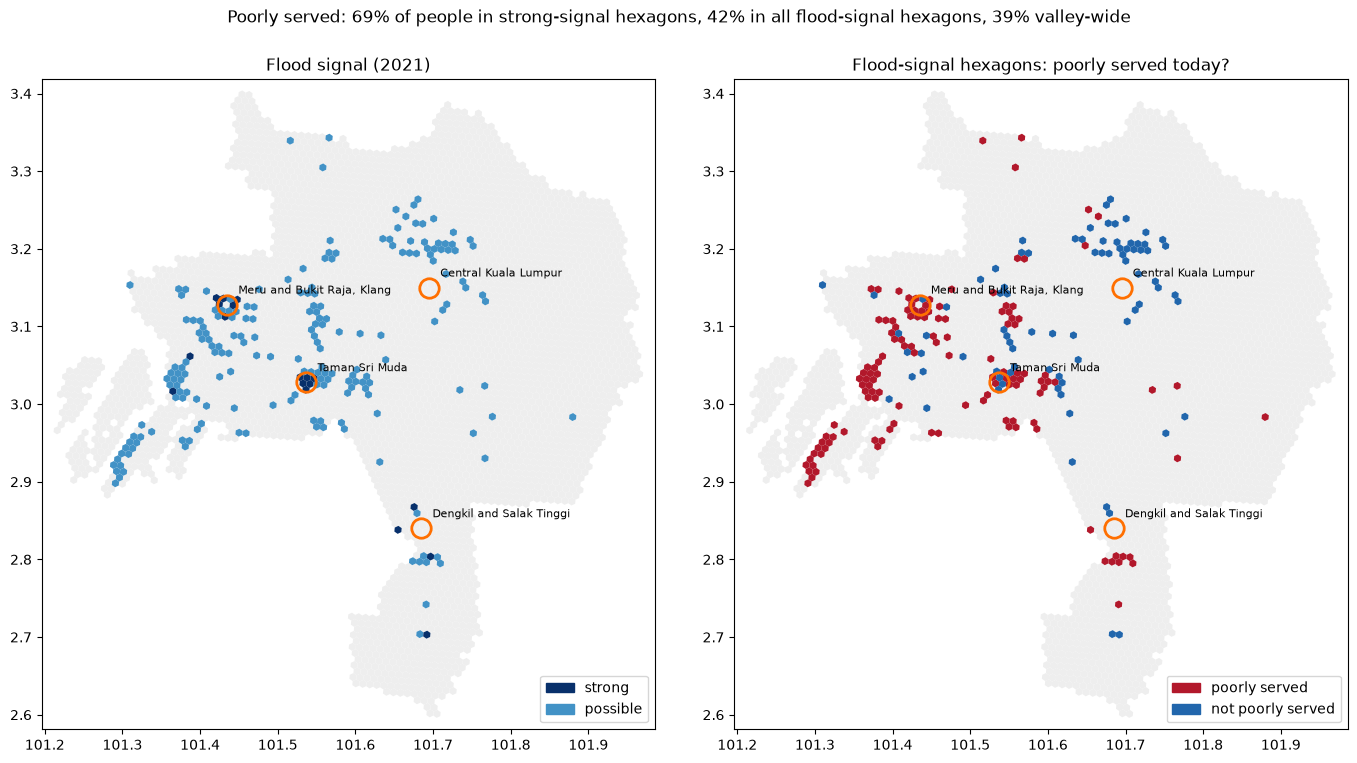

In [8]:
import h3
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.patches import Patch

def polys(cells):
    return [[(lon, lat) for lat, lon in h3.cell_to_boundary(c)] for c in cells]

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
for ax, title, colour_by in [(axes[0], "Flood signal (2021)", "tier"), (axes[1], "Flood-signal hexagons: poorly served today?", "poor")]:
    base = d[~d["flooded"]]
    ax.add_collection(PolyCollection(polys(base["h3"]), facecolor="#eeeeee", edgecolor="none"))
    fl = d[d["flooded"]]
    if colour_by == "tier":
        cols = fl["tier"].map({"strong": "#08306b", "possible": "#4292c6"})
        legend = [Patch(color="#08306b", label="strong"), Patch(color="#4292c6", label="possible")]
    else:
        cols = np.where(fl["poor"], "#b2182b", "#2166ac")
        legend = [Patch(color="#b2182b", label="poorly served"), Patch(color="#2166ac", label="not poorly served")]
    ax.add_collection(PolyCollection(polys(fl["h3"]), facecolor=list(cols), edgecolor="none"))
    for name, lat, lon, radius, note in STORY_PLACES:
        ax.plot(lon, lat, "o", mfc="none", mec="#ff6f00", ms=14, mew=2)
        ax.annotate(name, (lon, lat), xytext=(8, 8), textcoords="offset points", fontsize=8)
    ax.set_xlim(d["lon"].min() - 0.02, d["lon"].max() + 0.02)
    ax.set_ylim(d["lat"].min() - 0.02, d["lat"].max() + 0.02)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.legend(handles=legend, loc="lower right")
g = groups
fig.suptitle(f"Poorly served: {g['strong']['poor_share']:.0%} of people in strong-signal hexagons, "
             f"{g['flooded']['poor_share']:.0%} in all flood-signal hexagons, {g['valley']['poor_share']:.0%} valley-wide")
plt.tight_layout(rect=[0, 0, 1, 0.95])
OUTPUT.mkdir(exist_ok=True)
plt.savefig(OUTPUT / "stage5_story_preview.png", dpi=110)
plt.show()

___
**END**